In [ ]:
!unzip -q dataset.zip

Mounted at /content/drive
Found 82 files belonging to 3 classes.

[INFO] Clases detectadas (3):
['corrosion', 'fisura', 'sano']

[INFO] Total de imágenes: 82

========== DIVISIÓN DEL DATASET ==========
Entrenamiento: 57 imágenes (69.5%)
Validación:    16 imágenes (19.5%)
Prueba:        9 imágenes (11.0%)
2019640/2019640 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

FASE 1: ENTRENANDO CABEZAL CLASIFICADOR
Epoch 1/25
8/8 ━━━━━━━━━━━━━━━━━━━━ 37s 2s/step - accuracy: 0.2632 - loss: 1.4584 - val_accuracy: 0.6250 - val_loss: 0.8720
Epoch 2/25
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 200ms/step - accuracy: 0.5614 - loss: 0.9467 - val_accuracy: 0.8125 - val_loss: 0.6046
Epoch 3/25
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 303ms/step - accuracy: 0.6491 - loss: 0.7175 - val_accuracy: 0.8125 - val_loss: 0.4181
Epoch 4/25
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 191ms/step - accuracy: 0.6316 - loss: 0.8083 - val_accuracy: 0.7500 - val_loss: 0.4576
Epoch 5/25
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 197ms/step - accuracy: 0.8246 - loss: 0.5357 - val_accuracy: 0.

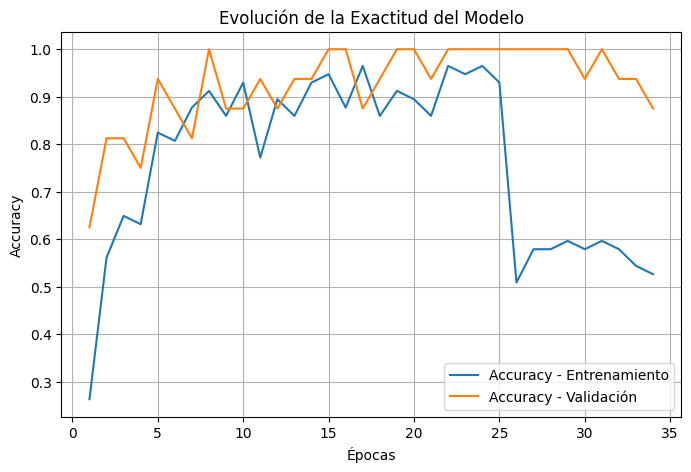

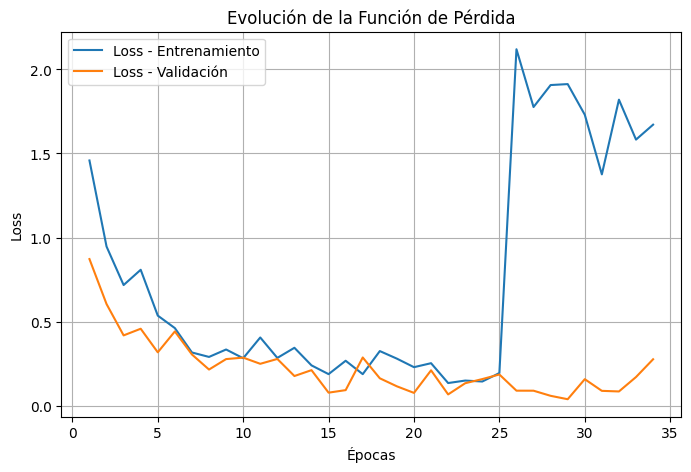


EVALUACIÓN FINAL CON EL CONJUNTO DE PRUEBA
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 1.0000 - loss: 0.0780 

RESULTADOS FINALES:
Test Loss: 0.0780
Test Accuracy: 100.00%

REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

   corrosion     0.8000    1.0000    0.8889         4
      fisura     1.0000    1.0000    1.0000         4
        sano     0.0000    0.0000    0.0000         1

    accuracy                         0.8889         9
   macro avg     0.6000    0.6667    0.6296         9
weighted avg     0.8000    0.8889    0.8395         9



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


<Figure size 700x600 with 0 Axes>

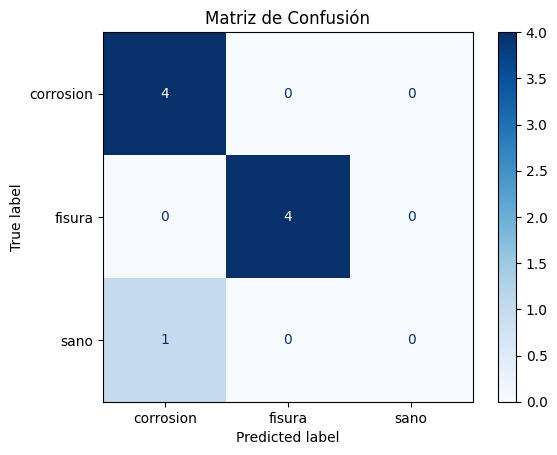


[INFO] Modelo Keras guardado en:
/content/drive/MyDrive/EntrenamientoIA/modelo_shm_multiclase.keras
Saved artifact at '/tmp/tmp4unu43u2'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='keras_tensor_154')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  136661098269200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136661098269392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136661098271504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136661098271696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136661098270544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136661098271120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136661098272272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136661098272080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136661098272464: TensorSpec(shape=(), dtype=tf.re

In [ ]:
import os
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
from google.colab import drive

# 0. Montar Google Drive
drive.mount('/content/drive')

# Rutas y parámetros
DATASET_PATH = '/content/drive/MyDrive/EntrenamientoIA/imagenes_corrosion_fisura_sano'
IMG_SIZE = (128, 128)
BATCH_SIZE = 8  # Ajustado para procesar más rápido si la VRAM lo permite
AUTOTUNE = tf.data.AUTOTUNE

# 1. Cargar el dataset en modo multiclase (categorical)
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    validation_split=0.2,
    subset='training',
    seed=123
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    validation_split=0.2,
    subset='validation',
    seed=123
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print(f"[INFO] Clases detectadas ({NUM_CLASSES}): {class_names}")

# Optimización en RAM para acelerar la carga de lotes
train_ds = train_ds.cache().shuffle(100).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

# 2. Aumento de datos
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.3),
    layers.RandomZoom(0.2),
    layers.RandomContrast(0.2),
])

# 3. Arquitectura MobileNetV2 (Extractor de características)
base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights='imagenet',
    alpha=0.35
)
base_model.trainable = False

# El catálogo de capas exige la regularización justo antes de la Dense de salida
model = models.Sequential([
    layers.Input(shape=IMG_SIZE + (3,)),
    data_augmentation,
    layers.Rescaling(1./127.5, offset=-1),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation='softmax')  # 3 salidas con Softmax
])

# Compilación para multiclase
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Guardar los mejores pesos para evitar sobreajuste
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

print("\n[INFO] FASE 1: Entrenando cabezal clasificador...")
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=[early_stop]
)

# 3.5 Fine-Tuning: Descongelar las últimas capas del MobileNetV2
base_model.trainable = True
for layer in base_model.layers[:100]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),  # Tasa de aprendizaje muy baja
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("\n[INFO] FASE 2: Fine-Tuning de características locales...")
history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stop]
)

# 4. Exportar y Cuantizar a TensorFlow Lite
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()

TFLITE_PATH = '/content/modelo_shm_multiclase.tflite'
with open(TFLITE_PATH, 'wb') as f:
    f.write(tflite_model)

print("\n=======================================================")
print(f" ¡ÉXITO! Modelo guardado en: {TFLITE_PATH}")
print("=======================================================")